# 🚀 Deploying a Machine Learning Model — Customer Churn Prediction

> **From a Jupyter notebook to a web service in the cloud:**
> `pickle` → **Flask** → **Pipenv** → **Docker** → **AWS Elastic Beanstalk**

A telecom company wants to know **which customers are about to leave (churn)** so the
marketing team can send them a discount *before* they go. We already trained a
churn model (logistic regression on the Telco Customer Churn dataset). A model that
only lives inside a notebook is not useful to anyone else though. In this project we
**deploy** it: other programs send a customer's data over the network and get
back a churn prediction.

| § | Section | Key idea |
|---|---------|----------|
| 1 | Intro: what is deployment? | the layers of a deployed model |
| 2 | Recap: training the churn model | data → features → model (AUC ≈ 0.86) |
| 3 | Saving and loading the model *(5.2)* | `pickle`, notebook → script |
| 4 | Web services: introduction to Flask *(5.3)* | HTTP, `GET /ping` → `pong` |
| 5 | Serving the churn model with Flask *(5.4)* | `POST /predict`, `requests`, gunicorn / waitress |
| 6 | Python virtual environments: Pipenv *(5.5)* | `Pipfile`, `Pipfile.lock`, comparison of tools |
| 7 | Environment management: Docker *(5.6)* | images, containers, `Dockerfile`, ports |
| 8 | Deployment to the cloud: AWS Elastic Beanstalk *(5.7)* | `eb init` → `eb create` → public URL |
| 9 | Summary *(5.8)* & explore more *(5.9)* | what to try next |

### 📁 Project files

| File | What it does |
|------|--------------|
| `model_deployment.ipynb` | this notebook: the full story with explanations |
| `train.py` | trains the model and saves it to `model_C=1.0.bin` (notebook → script) |
| `predict_offline.py` | loads the model and scores one customer, no web service |
| `ping.py` | the smallest Flask web service (`/ping` → `pong`) |
| `predict.py` | **the churn web service** (`POST /predict`) |
| `predict_client.py` | client that sends a customer to the service, local or in the cloud |
| `customer.json` | example customer used by the client and by `curl` |
| `Pipfile`, `Pipfile.lock` | Python environment (Pipenv) |
| `requirements.txt` | the minimal, pinned packages installed in the Docker image |
| `Dockerfile`, `.dockerignore` | how to build the Docker image |
| `.ebignore` | which files are *not* uploaded to Elastic Beanstalk |
| `notebook_helpers.py` | plotting style, diagrams and a background server used by this notebook |
| `data/churn_telco_data.csv` | the dataset |

### ❓ Questions answered in this notebook

| Question | Where |
|----------|-------|
| What are the steps of deploying a model? Is *model → web service → pipenv → Docker → cloud* correct? | §1 |
| What is a web service? Examples? Is AWS a web service? Is Google? | §4.1 |
| Flask is free, so why pay for AWS? | §4.2 |
| What do HTTP methods (`GET`, `POST`, …) mean? | §4.3 |
| Why doesn't `app.run()` work inside Jupyter? | §4.5 |
| Do I need to buy a host to test my service? curl / browser? | §4.6 |
| Why `float()` and `bool()` in the response? Do we need `jsonify`? | §5.1 |
| Isn't sending requests to `localhost` pointless? | §5.4 |
| Why did `!pip install gunicorn # and then …` fail with `no such option: --bind`? | §5.7 |
| venv, virtualenv, conda, pipenv, poetry, uv: pros, cons, which is best? | §6.2 |
| What are `Pipfile` and `Pipfile.lock`? | §6.4 |
| Why Docker? Does Docker run Linux, even on Windows? Windows / macOS containers? | §7.1 – 7.2 |
| Docker vs virtual machines? | §7.3 |
| Image vs container: many containers from one image? | §7.4 |
| What does `docker run -it --rm python:3.12-slim` mean? | §7.5 |
| What are `WORKDIR`, `COPY`, `ENTRYPOINT` in a Dockerfile? | §7.7 |
| Do we need a virtual env inside Docker? | §7.8 |
| `-p 127.0.0.1:8080:9696`: which port is which? Server-side vs client-side steps? | §7.9 |
| AWS, GCP, Azure, Heroku, PythonAnywhere: what's the difference? | §8.1 |
| What does Elastic Beanstalk do? What does scaling up/down mean? | §8.2 |

## ⚙️ Setup

This notebook runs in the project's **Pipenv** environment (see §6). To start it:

```bash
pipenv install --dev      # once: create the environment from Pipfile.lock
pipenv run jupyter lab    # or select the Pipenv kernel in VS Code
```

In [1]:
import json
import os
import sys
import time
import pickle
import importlib.metadata as metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import requests
import sklearn

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve

import notebook_helpers as nh                      # plotting style, diagrams, background server
from notebook_helpers import BLUE, ORANGE, AQUA, RED, INK2, MUTED

%matplotlib inline
nh.set_plot_style()

print(f'Python {sys.version.split()[0]} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}')

Python 3.12.7 | pandas 3.0.6 | scikit-learn 1.9.1


---
# 1. Intro — what does "deploying a model" mean? *(5.1)*

Once a model is trained we want to **use** it. Right now it only exists in this notebook's memory:
if the marketing team's system wants a churn score, it can't get one. **Deployment** means
putting the model somewhere other programs can **send a request** (a customer) and **get a
response** (the churn probability), at any time, without us running a notebook.

**Your summary was:**
*model → web service (Flask) → environment for Python dependencies (Pipenv) → environment for
system dependencies (Docker) → cloud service (AWS)*

✅ **That's correct.** It helps even more to see these as **layers that wrap each other**
rather than as a chain. Each layer solves one problem:

| Layer | Tool here | Problem it solves | Alternatives |
|-------|-----------|-------------------|--------------|
| **Model** | `pickle` file | keep the trained model without retraining | joblib, skops, ONNX |
| **Web service** | Flask + gunicorn | let other programs call the model over the network | FastAPI, Django, BentoML |
| **Python environment** | Pipenv | exactly the right *library* versions (`scikit-learn==1.9.1`) | venv + pip, conda, poetry, uv |
| **System environment** | Docker | exactly the right *OS + Python + system libraries*, the same everywhere | virtual machines, Podman |
| **Cloud** | AWS Elastic Beanstalk | an always-on, publicly reachable computer that can scale | GCP Cloud Run, Azure, Heroku, … |

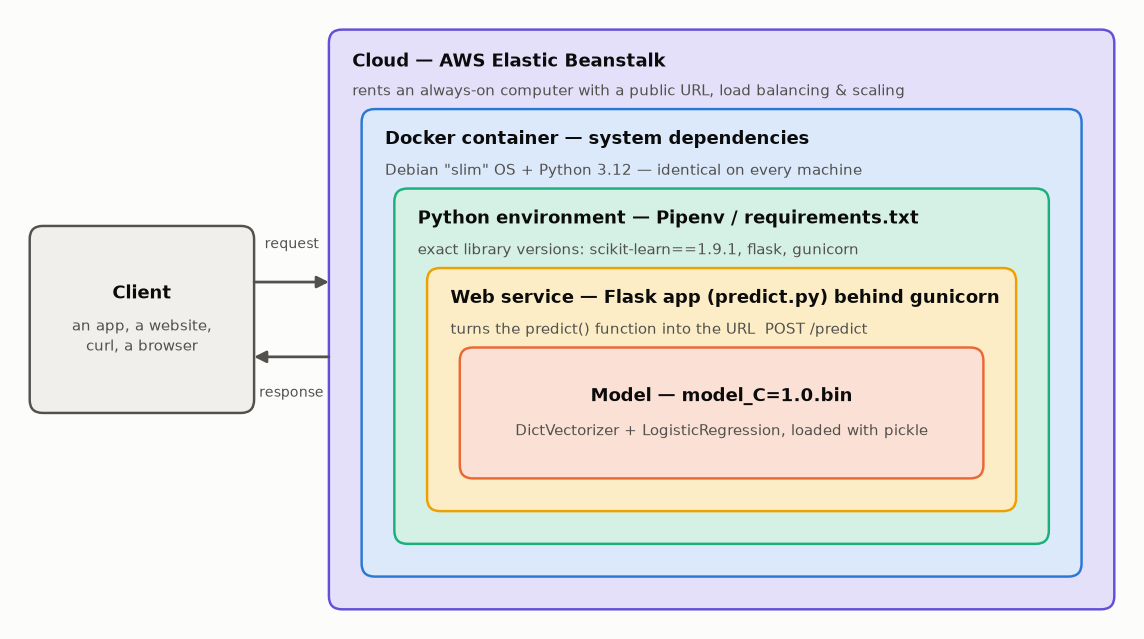

In [2]:
nh.draw_deployment_stack()

**How the client talks to the service:** the client sends a customer as JSON in an HTTP
request; the service answers with JSON. That's the whole contract. The client doesn't need
Python, scikit-learn or the model file.

The project follows the same order as this notebook:

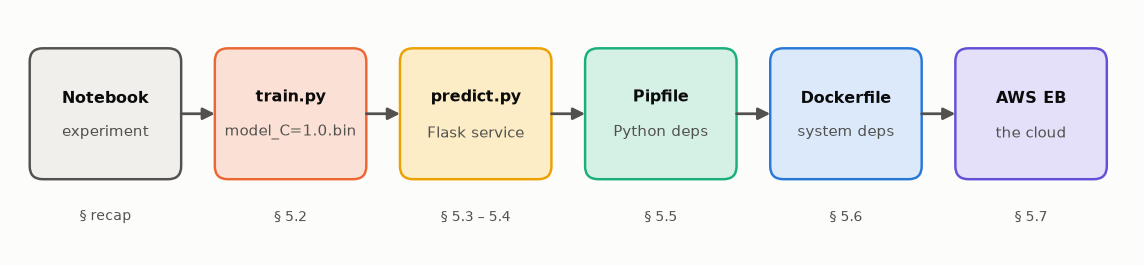

In [3]:
nh.draw_project_pipeline()

---
# 2. Recap — training the churn model

This is the model from the previous project, unchanged. We need it in memory before we can save it.

## 2.1 Load and clean the data

In [4]:
df = pd.read_csv('data/churn_telco_data.csv')

# normalise column names: 'Monthly Charges' -> 'monthly_charges'
df.columns = df.columns.str.lower().str.replace(' ', '_')

# normalise the text values: 'Fiber optic' -> 'fiber_optic'
# (select_dtypes works with both pandas 2 'object' and pandas 3 'str' columns)
string_columns = df.select_dtypes(include=['object', 'string']).columns
for col in string_columns:
    df[col] = df[col].str.lower().str.replace(' ', '_')

# totalcharges is read as text because brand-new customers have a blank value -> 0
df['totalcharges'] = pd.to_numeric(df['totalcharges'], errors='coerce').fillna(0)

# target variable: 1 = the customer churned (left), 0 = stayed
df['churn'] = (df['churn'] == 'yes').astype(int)

print(f'{df.shape[0]:,} customers × {df.shape[1]} columns')
df.head()

7,043 customers × 21 columns


,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,7590-vhveg,female,0,yes,no,1,no,no_phone_service,dsl,no,...,no,no,no,no,month-to-month,yes,electronic_check,29.85,29.85,0
1,5575-gnvde,male,0,no,no,34,yes,no,dsl,yes,...,yes,no,no,no,one_year,no,mailed_check,56.95,1889.50,0
2,3668-qpybk,male,0,no,no,2,yes,no,dsl,yes,...,no,no,no,no,month-to-month,yes,mailed_check,53.85,108.15,1
3,7795-cfocw,male,0,no,no,45,no,no_phone_service,dsl,yes,...,yes,yes,no,no,one_year,no,bank_transfer_(automatic),42.30,1840.75,0
4,9237-hqitu,female,0,no,no,2,yes,no,fiber_optic,no,...,no,no,no,no,month-to-month,yes,electronic_check,70.70,151.65,1


## 2.2 A quick look at the data

About one in four customers churns. Month-to-month contracts and new customers (short tenure)
churn the most: these are the signals the model will learn.

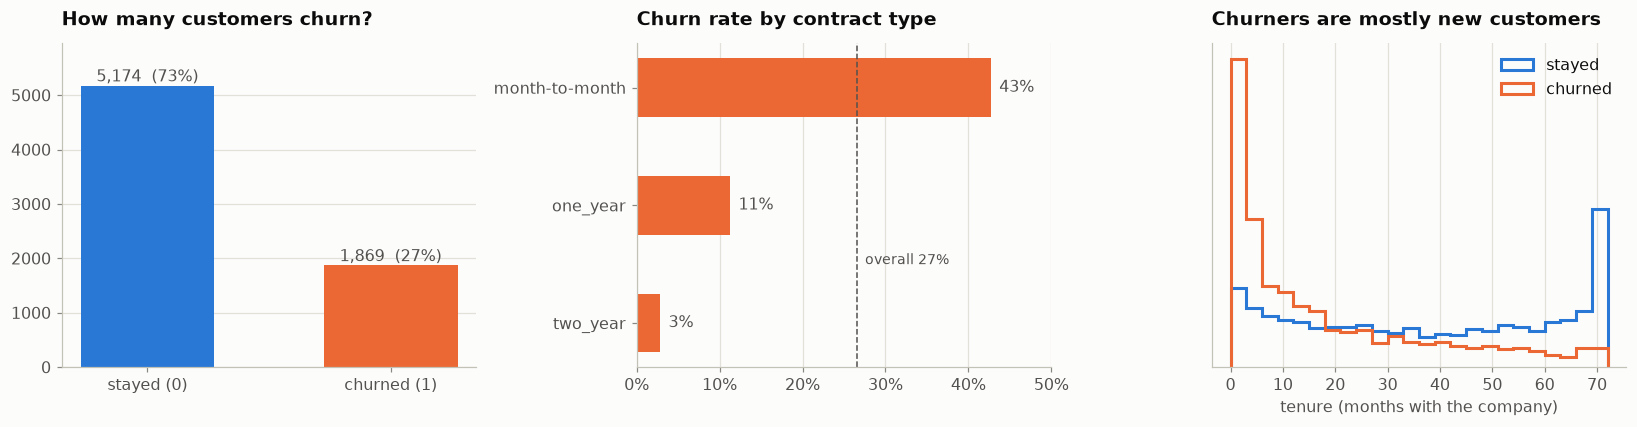

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1) class balance
counts = df['churn'].value_counts().sort_index()
axes[0].bar(['stayed (0)', 'churned (1)'], counts.values, color=[BLUE, ORANGE], width=0.55)
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 80, f'{v:,}  ({v / len(df):.0%})', ha='center', color=INK2)
axes[0].set_ylim(0, counts.max() * 1.15)
axes[0].grid(axis='x', visible=False)
axes[0].set_title('How many customers churn?')

# 2) churn rate per contract type
rate = df.groupby('contract')['churn'].mean().sort_values()
axes[1].barh(rate.index, rate.values, color=ORANGE, height=0.5)
for y, v in enumerate(rate.values):
    axes[1].text(v + 0.01, y, f'{v:.0%}', va='center', color=INK2)
axes[1].axvline(df['churn'].mean(), color=INK2, ls='--', lw=1)
axes[1].text(df['churn'].mean() + 0.01, 0.5, f"overall {df['churn'].mean():.0%}", color=INK2, fontsize=9)
axes[1].xaxis.set_major_formatter(PercentFormatter(1))
axes[1].set_xlim(0, 0.5)
axes[1].grid(axis='y', visible=False)
axes[1].set_title('Churn rate by contract type')

# 3) tenure distribution per class
bins = np.arange(0, 75, 3)
for label, color, name in [(0, BLUE, 'stayed'), (1, ORANGE, 'churned')]:
    axes[2].hist(df.loc[df['churn'] == label, 'tenure'], bins=bins, density=True,
                 histtype='step', lw=2, color=color, label=name)
axes[2].set_xlabel('tenure (months with the company)')
axes[2].set_yticks([])
axes[2].legend()
axes[2].set_title('Churners are mostly new customers')

plt.tight_layout()
plt.show()

## 2.3 Train / test split and features

In [6]:
# 80% for training + validation, 20% held out as the final test set
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)

numerical = ['tenure', 'monthlycharges', 'totalcharges']

categorical = [
    'gender',
    'seniorcitizen',
    'partner',
    'dependents',
    'phoneservice',
    'multiplelines',
    'internetservice',
    'onlinesecurity',
    'onlinebackup',
    'deviceprotection',
    'techsupport',
    'streamingtv',
    'streamingmovies',
    'contract',
    'paperlessbilling',
    'paymentmethod',
]

print(f'train+val: {len(df_full_train):,} rows | test: {len(df_test):,} rows')

train+val: 5,634 rows | test: 1,409 rows


## 2.4 Training and prediction functions

`DictVectorizer` turns each customer (a dict) into a numeric vector: categorical features are
one-hot encoded (`contract=month-to-month` → 1/0), numerical ones are kept as they are.
**The fitted vectorizer is part of the model:** we must save it together with the logistic
regression, otherwise a new customer can't be encoded the same way.

In [7]:
def train(df_train, y_train, C=1.0):
    """Fit the DictVectorizer and the logistic regression on a training frame."""
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(C=C, max_iter=5000)
    model.fit(X_train, y_train)

    return dv, model


def predict(df, dv, model):
    """Churn probability for every row of `df`."""
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

## 2.5 Validation with K-fold cross-validation

In [8]:
C = 1.0         # inverse regularisation strength
n_splits = 5    # number of folds

kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train['churn'].values
    y_val = df_val['churn'].values

    dv, model = train(df_train, y_train, C=C)
    y_pred = predict(df_val, dv, model)

    scores.append(roc_auc_score(y_val, y_pred))

print(f'C={C}  AUC = {np.mean(scores):.3f} ± {np.std(scores):.3f}')

C=1.0  AUC = 0.842 ± 0.007


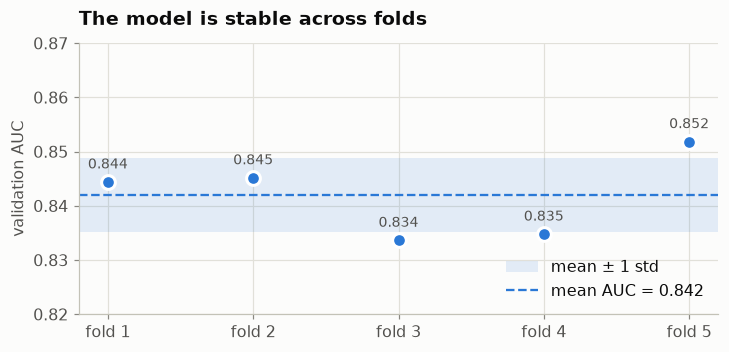

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 3.2))
folds = np.arange(n_splits)
mean, std = np.mean(scores), np.std(scores)

ax.axhspan(mean - std, mean + std, color=BLUE, alpha=0.12, lw=0, label='mean ± 1 std')
ax.axhline(mean, color=BLUE, lw=1.5, ls='--', label=f'mean AUC = {mean:.3f}')
ax.plot(folds, scores, 'o', ms=9, color=BLUE, mec='white', mew=2)
for f, s in zip(folds, scores):
    ax.text(f, s + 0.0025, f'{s:.3f}', ha='center', color=INK2, fontsize=9)

ax.set_xticks(folds, [f'fold {f + 1}' for f in folds])
ax.set_ylim(0.82, 0.87)
ax.set_ylabel('validation AUC')
ax.set_title('The model is stable across folds')
ax.legend(loc='lower right')
plt.show()

## 2.6 The final model

We train on the full training set and check it **once** on the test set.

In [10]:
dv, model = train(df_full_train, df_full_train['churn'].values, C=C)

y_test = df_test['churn'].values
y_pred = predict(df_test, dv, model)

auc = roc_auc_score(y_true=y_test, y_score=y_pred)
print(f'Test AUC = {auc:.3f}')

Test AUC = 0.858


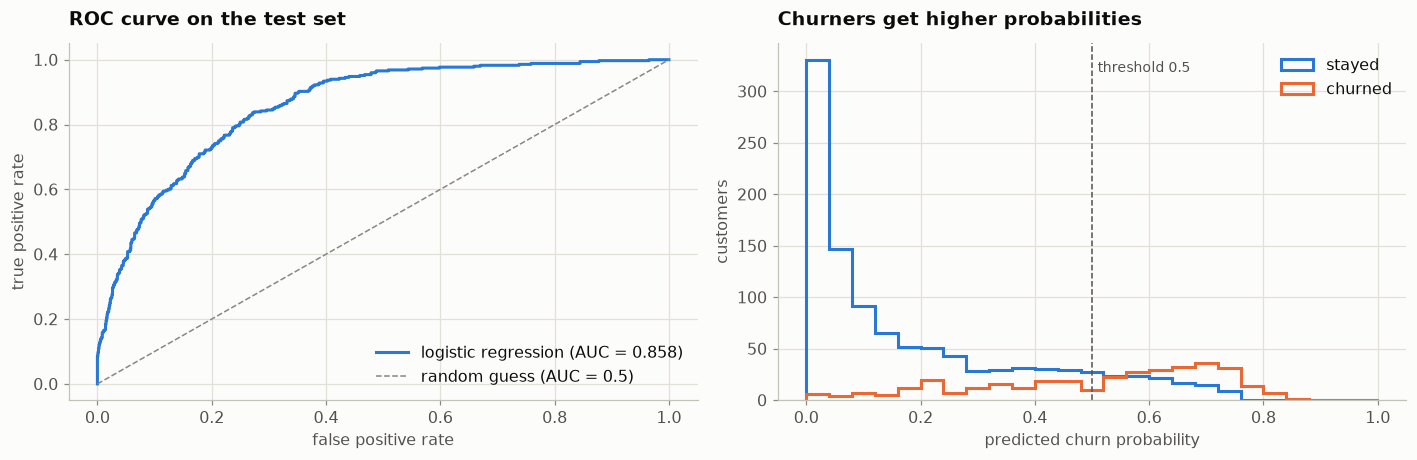

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))

# ROC curve
fpr, tpr, _ = roc_curve(y_test, y_pred)
axes[0].plot(fpr, tpr, color=BLUE, label=f'logistic regression (AUC = {auc:.3f})')
axes[0].plot([0, 1], [0, 1], color=MUTED, ls='--', lw=1, label='random guess (AUC = 0.5)')
axes[0].set_xlabel('false positive rate')
axes[0].set_ylabel('true positive rate')
axes[0].legend(loc='lower right')
axes[0].set_title('ROC curve on the test set')

# predicted probabilities per true class
bins = np.linspace(0, 1, 26)
axes[1].hist(y_pred[y_test == 0], bins=bins, histtype='step', lw=2, color=BLUE, label='stayed')
axes[1].hist(y_pred[y_test == 1], bins=bins, histtype='step', lw=2, color=ORANGE, label='churned')
axes[1].axvline(0.5, color=INK2, ls='--', lw=1)
axes[1].text(0.51, axes[1].get_ylim()[1] * 0.92, 'threshold 0.5', color=INK2, fontsize=9)
axes[1].set_xlabel('predicted churn probability')
axes[1].set_ylabel('customers')
axes[1].legend()
axes[1].set_title('Churners get higher probabilities')

plt.tight_layout()
plt.show()

**What did the model learn?** Positive coefficients push towards churn, negative ones towards staying.

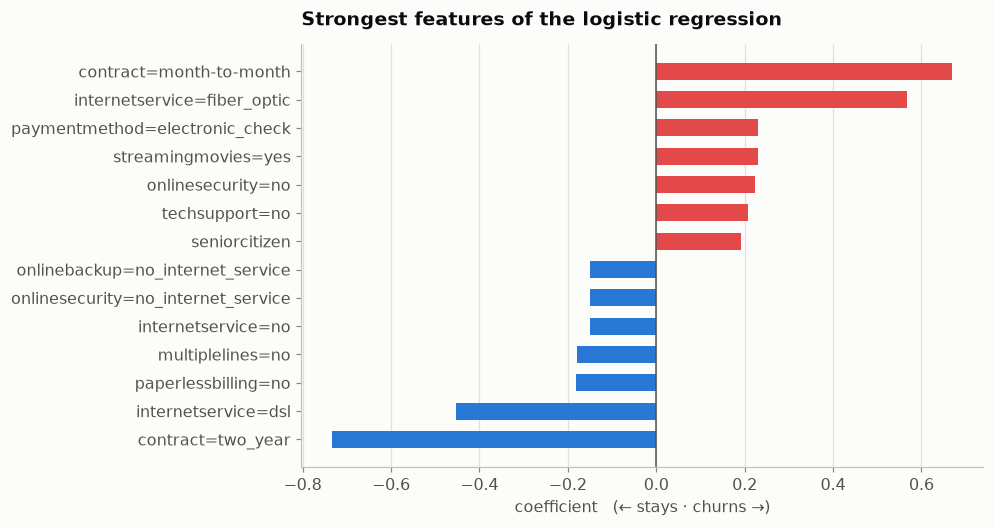

In [12]:
coef = pd.Series(model.coef_[0], index=dv.get_feature_names_out()).sort_values()
top = pd.concat([coef.head(7), coef.tail(7)])

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top.values, color=[BLUE if c < 0 else RED for c in top.values], height=0.6)
ax.axvline(0, color=INK2, lw=1)
ax.grid(axis='y', visible=False)
ax.set_xlabel('coefficient   (← stays · churns →)')
ax.set_title('Strongest features of the logistic regression')
plt.show()

---
# 3. Saving and loading the model *(5.2)*

**Goal:** save the model to a file with `pickle`, load it back, and turn the notebook into a Python script.

The web service must not retrain the model on every start. We train **once**, save the result to
a file, and the service just **loads** it. [`pickle`](https://docs.python.org/3/library/pickle.html)
is Python's built-in module for saving (almost) any Python object to bytes and back.

## 3.1 Save the model

In [13]:
model_file = f'model_C={C}.bin'

# 'wb' = write binary. The `with` block closes the file automatically
# (pickle.dump(obj, open(...)) leaves the file open until Python garbage-collects it)
with open(model_file, 'wb') as f_out:
    pickle.dump((dv, model), f_out)      # save BOTH the vectorizer and the model

print(f'saved {model_file}  ({os.path.getsize(model_file):,} bytes)')

saved model_C=1.0.bin  (2,459 bytes)


## 3.2 Load the model

Usually this happens in **another process**, e.g. the web service. Here we check that the loaded
model gives exactly the same predictions.

In [14]:
# 'rb' = read binary
with open(model_file, 'rb') as f_in:
    dv_loaded, model_loaded = pickle.load(f_in)

y_pred_loaded = predict(df_test, dv_loaded, model_loaded)

print(f'AUC of the loaded model: {roc_auc_score(y_test, y_pred_loaded):.4f}')
print('identical predictions  :', np.array_equal(y_pred, y_pred_loaded))

AUC of the loaded model: 0.8585
identical predictions  : True


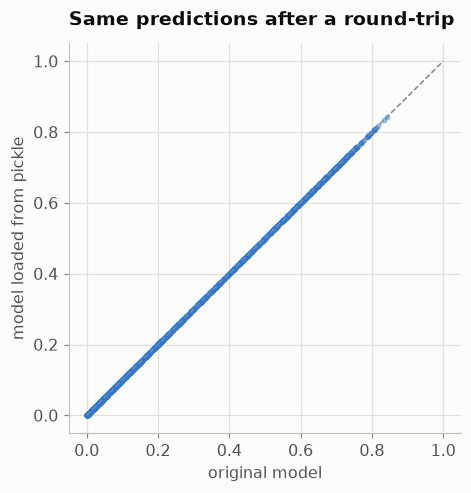

In [15]:
fig, ax = plt.subplots(figsize=(4.6, 4.6))
ax.plot([0, 1], [0, 1], color=MUTED, lw=1, ls='--')
ax.scatter(y_pred, y_pred_loaded, s=14, color=BLUE, alpha=0.5, lw=0)
ax.set_xlabel('original model')
ax.set_ylabel('model loaded from pickle')
ax.set_title('Same predictions after a round-trip')
plt.show()

> ⚠️ **Two things to know about pickle**
> 1. **Never unpickle files you don't trust.** Loading a pickle can run arbitrary code.
> 2. **Load with the same library versions.** A model pickled with scikit-learn 1.9.1 should be
>    loaded with scikit-learn 1.9.1; other versions emit an `InconsistentVersionWarning` and may
>    break or behave differently. **This is why we pin versions** in Pipenv (§6) and Docker (§7).

## 3.3 Predict a single customer

In production the service receives **one customer at a time**, as a dictionary (from JSON).

In [16]:
customer = {
    'gender': 'female',
    'seniorcitizen': 0,
    'partner': 'yes',
    'dependents': 'no',
    'phoneservice': 'no',
    'multiplelines': 'no_phone_service',
    'internetservice': 'dsl',
    'onlinesecurity': 'no',
    'onlinebackup': 'yes',
    'deviceprotection': 'no',
    'techsupport': 'no',
    'streamingtv': 'no',
    'streamingmovies': 'no',
    'contract': 'month-to-month',
    'paperlessbilling': 'yes',
    'paymentmethod': 'electronic_check',
    'tenure': 1,
    'monthlycharges': 29.85,
    'totalcharges': 29.85,
}   # the same customer is stored in customer.json

**Option 1:** wrap the dict in a one-row DataFrame and reuse our `predict()` function:

In [17]:
df_one_customer = pd.DataFrame([customer])
predict(df_one_customer, dv_loaded, model_loaded)

array([0.62789273])

**Option 2 (what the web service does):** give the dict straight to the vectorizer. No pandas needed,
so the service has fewer dependencies. This is what one-hot encoding looks like for this customer:

In [18]:
X = dv_loaded.transform([customer])          # a list of dicts -> a 2-D matrix (1 row)

encoded = pd.Series(X[0], index=dv_loaded.get_feature_names_out())
print(f'{X.shape[1]} features, {(encoded != 0).sum()} of them non-zero:')
encoded[encoded != 0]

45 features, 18 of them non-zero:


contract=month-to-month            1.00
dependents=no                      1.00
deviceprotection=no                1.00
gender=female                      1.00
internetservice=dsl                1.00
monthlycharges                    29.85
multiplelines=no_phone_service     1.00
onlinebackup=yes                   1.00
onlinesecurity=no                  1.00
paperlessbilling=yes               1.00
partner=yes                        1.00
paymentmethod=electronic_check     1.00
phoneservice=no                    1.00
streamingmovies=no                 1.00
streamingtv=no                     1.00
techsupport=no                     1.00
tenure                             1.00
totalcharges                      29.85
dtype: float64

In [19]:
churn_probability = model_loaded.predict_proba(X)[0, 1]   # row 0, column 1 = P(churn)
churn_label = model_loaded.predict(X)[0]                    # same thing, cut at 0.5

print(f'predict_proba -> {churn_probability:.3f}  (probability of churn)')
print(f'predict       -> {churn_label}      (1 = churn, using a 0.5 threshold)')

predict_proba -> 0.628  (probability of churn)
predict       -> 1      (1 = churn, using a 0.5 threshold)


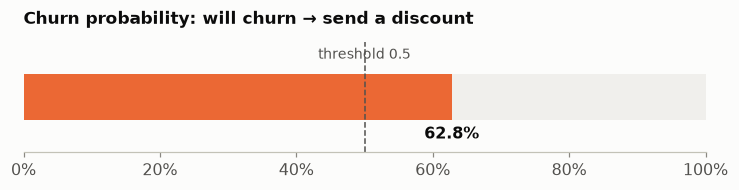

In [20]:
def plot_churn_gauge(probability, threshold=0.5):
    """A horizontal 0-1 bar showing one churn probability against the threshold."""
    fig, ax = plt.subplots(figsize=(8, 1.3))
    ax.barh(0, 1, color='#f0efec', height=0.5)
    ax.barh(0, probability, color=ORANGE if probability >= threshold else BLUE, height=0.5)
    ax.axvline(threshold, color=INK2, ls='--', lw=1)
    ax.text(threshold, 0.42, f'threshold {threshold}', ha='center', color=INK2, fontsize=9)
    ax.text(probability, -0.45, f'{probability:.1%}', ha='center', fontweight='bold')
    ax.set_xlim(0, 1)
    ax.set_ylim(-0.6, 0.6)
    ax.set_yticks([])
    ax.grid(False)
    ax.spines['left'].set_visible(False)
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    decision = 'will churn → send a discount' if probability >= threshold else 'will stay'
    ax.set_title(f'Churn probability: {decision}', fontsize=11)
    plt.show()


plot_churn_gauge(churn_probability)

## 3.4 Turning the notebook into a Python script

A web server can't run a notebook, so the code has to live in `.py` files. Jupyter can export the
code cells for us
([source](https://stackoverflow.com/a/19779226)):

```bash
jupyter nbconvert --to script model_deployment.ipynb     # -> model_deployment.py
```

The export contains *every* cell (plots, experiments), so we clean it up into two scripts:

* **`train.py`**: load data → cross-validate → train → save `model_C=1.0.bin`
* **`predict_offline.py`**: load `model_C=1.0.bin` → score one customer

In [21]:
nh.show_file('predict_offline.py')

📄 **`predict_offline.py`**
```python
"""
Predict churn for one customer *without* a web service.

This is the first step of deployment: the notebook code turned into a script
that loads the saved model and scores a customer. It only works on the
machine where it runs - section 5.3 turns it into a web service.

Usage:
    pipenv run python predict_offline.py
"""

import json
import pickle

MODEL_FILE = 'model_C=1.0.bin'
CHURN_THRESHOLD = 0.5

with open(MODEL_FILE, 'rb') as f_in:
    dv, model = pickle.load(f_in)


def predict(customer):
    """Return (will_churn, churn_probability) for one customer dict."""
    X = dv.transform([customer])
    churn_probability = model.predict_proba(X)[0, 1]
    return bool(churn_probability >= CHURN_THRESHOLD), float(churn_probability)


if __name__ == '__main__':
    with open('customer.json', encoding='utf-8') as f_in:
        customer = json.load(f_in)

    will_churn, churn_probability = predict(customer)
    print(f'churn probability = {churn_probability:.3f}  ->  churn = {will_churn}')
```

Run it from the notebook. `sys.executable` is the Python of **this kernel** (the Pipenv
environment). A bare `!python` could start a different Python from your PATH that has another
scikit-learn version installed.

In [22]:
!"{sys.executable}" predict_offline.py

churn probability = 0.628  ->  churn = True


This works, but **only on this computer, for whoever can run Python here**. Next we make the model
reachable over the network.

---
# 4. Web services: introduction to Flask *(5.3)*

## 4.1 What is a web service?

A **web service** is a program that runs on a computer, **listens at a network address**
(like `http://localhost:9696/predict`), receives **requests**, and sends back **responses**,
usually as JSON. You talk to it over the network with the HTTP protocol, the same protocol
your browser uses.

> 🍽️ **Analogy:** a web service is a restaurant counter. You hand over an order (the request), the
> kitchen does the work you never see, and you get your food back (the response). You don't need
> to know how to cook, only how to order.

| Example | You send | You get back |
|---------|----------|--------------|
| A weather API | a city name | temperature, forecast (JSON) |
| Google Maps API | two addresses | a route, travel time |
| Stripe (payments) | card token + amount | payment confirmed / declined |
| OpenAI / Anthropic API | a prompt | generated text |
| GitHub API | a repository name | its stars, issues, commits |
| **Our churn service** | **a customer** | **churn probability** |

**Website or web service?** A *website* returns HTML pages for **humans**; a *web service* (API)
returns data for **programs**. Google Search is mainly a website, and Google also offers many web
services (Maps, Translate, …) for programs.

**Is AWS a web service?** Not in the sense of our Flask app. **AWS is a cloud provider**: it rents
out computers, storage and networking. Many AWS products are controlled through web service
APIs (that's how the `eb` command talks to AWS), but AWS is where web services **run**. It isn't
one web service.

## 4.2 "Flask is free, so why pay for AWS?"

They solve **different problems**:

| | **Flask** (software) | **AWS / any cloud** (infrastructure) |
|---|---|---|
| What it is | a Python library | rented computers in a data centre |
| Gives you | turns a function into a URL that answers HTTP requests | a machine that is **always on**, has a **public address**, a fast network, backups |
| Also handles | routing, parsing requests, building responses | security groups, load balancing, auto-scaling, monitoring, logs |
| Cost | free | pay for what you use |

Flask without a server is a restaurant without a building. You *could* run it on your laptop,
but then it only works while your laptop is on, at home, and only you can reach it. The cloud
rents you the building on a busy street.

## 4.3 HTTP in two minutes

Every call to a web service is a **request** → **response** pair:

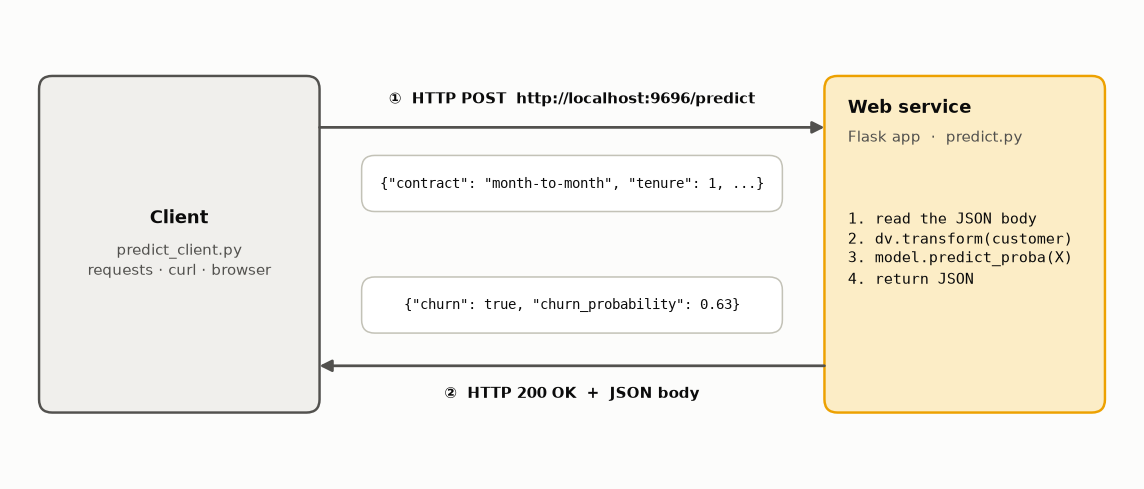

In [23]:
nh.draw_request_response()

The **method** says what kind of action the request is:

| Method | Meaning | Has a body? | Example |
|--------|---------|-------------|---------|
| `GET` | **read** something | no | open a web page, `/ping`, health check |
| `POST` | **send data** to be processed / created | yes | **`/predict` with a customer** |
| `PUT` | replace a resource | yes | update a whole user profile |
| `PATCH` | partially update a resource | yes | change only the e-mail |
| `DELETE` | delete a resource | no | remove a user |

**Why `POST` for predictions?** We send a whole customer (19 fields) in the request *body*. A `GET`
would have to cram it into the URL (`/predict?gender=female&tenure=1&...`). That's ugly, URLs have
length limits, and URLs end up in logs.

The response carries a **status code**:

| Code | Meaning | When you'll see it here |
|------|---------|-------------------------|
| `200 OK` | success | normal prediction |
| `400 Bad Request` | the client sent something wrong | body is not JSON |
| `404 Not Found` | no such URL | typo in the path |
| `405 Method Not Allowed` | wrong method for this URL | opening `/predict` in a browser (GET) |
| `500 Internal Server Error` | the server crashed | a bug in our code |

## 4.4 The simplest web service: ping → pong

We start from a plain Python function:

```python
def ping():
    return "pong"
```

To turn it into a web service, we create a Flask `app` and **decorate** the function with
`@app.route(...)`. The decorator registers the function as the handler for a URL path:

In [24]:
nh.show_file('ping.py')

📄 **`ping.py`**
```python
"""
The smallest possible web service: GET /ping -> "pong".

Run:   python ping.py
Test:  open http://localhost:9696/ping in a browser
       or  curl http://localhost:9696/ping
"""

from flask import Flask

app = Flask('ping')


# The decorator registers `ping` as the handler for the URL path /ping.
# The path can be anything ('/ping', '/hello', ...); `methods` lists the HTTP
# methods it accepts - GET is what a browser sends when you open a URL.
@app.route('/ping', methods=['GET'])
def ping():
    return 'pong'


if __name__ == '__main__':
    # host='0.0.0.0' -> listen on all network interfaces, not only localhost
    app.run(debug=True, host='0.0.0.0', port=9696)
```

* `Flask('ping')`: creates the application; the name is only a label.
* `@app.route('/ping', methods=['GET'])`: *when a `GET` request arrives at path `/ping`, call
  `ping()`*. The path is any name you like (`/ali` works too); it's the address of the function.
* `app.run(host='0.0.0.0', port=9696)`: starts a server that listens on port 9696.
* `debug=True`: auto-reloads when the code changes and shows detailed errors. **Development only.**

## 4.5 Why doesn't `app.run()` work in Jupyter?

You saw this yourself. There are two reasons:

1. **`app.run()` blocks.** It's an endless loop that waits for requests. The cell never finishes,
   so you can't run the next cell to *send* a request. The kernel is busy being the server.
2. **`debug=True` starts a reloader** that restarts the *current process* to watch your files. In
   Jupyter the current process is the kernel, so the restart fails or kills the kernel.

**Solutions:**
* the standard way: put the app in a `.py` file and run `python ping.py` in a **separate terminal**
  (this is what you did ✅);
* in a notebook: run the server in a **background thread** without the reloader.
  `nh.BackgroundServer` does exactly that, so this notebook can be a server *and* a client at the same time.

In [25]:
import ping                                    # our ping.py module (its app.run() is not executed on import)

ping_server = nh.BackgroundServer(ping.app, port=9696).start()

✅ Server running at http://127.0.0.1:9696  (in a background thread)

In [26]:
response = requests.get('http://localhost:9696/ping')

print('status code :', response.status_code)
print('content type:', response.headers['Content-Type'])
print('body        :', response.text)

127.0.0.1 - - [14/Oct/2026 00:26:40] "GET /ping HTTP/1.1" 200 -


status code : 200
content type: text/html; charset=utf-8
body        : pong


In [27]:
ping_server.stop()

🛑 Server at http://127.0.0.1:9696 stopped


## 4.6 Testing without buying a host: `localhost`

**Do I need to buy a server to test my service?** No. Run it on your own computer and call it
through **`localhost`**, a special name that always means *this machine*. The request never leaves
your computer.

| Address | Meaning |
|---------|---------|
| `localhost` / `127.0.0.1` | "this computer": only programs on the same machine can connect |
| `0.0.0.0` (when *listening*) | "all network interfaces": other machines (and Docker) can connect too |
| `192.168.x.x` | your machine's address in the local network (Wi-Fi / LAN) |
| `<name>.elasticbeanstalk.com` | a public address on the internet (§8) |

**Three ways to call the running `ping.py`** (start it in a terminal with `pipenv run python ping.py`):

1. **Browser:** open <http://localhost:9696/ping>. A browser sends `GET` requests, so this works
   for `/ping` but **not** for `/predict` (POST); there you'd get `405 Method Not Allowed`.
2. **curl** (command line):
   ```bash
   curl http://localhost:9696/ping
   ```
   💡 In Windows PowerShell, `curl` is an alias for `Invoke-WebRequest`; type **`curl.exe`** to get real curl.
3. **Python `requests`**, as in the cell above. This is how other programs call the service.

---
# 5. Serving the churn model with Flask *(5.4)*

## 5.1 The prediction service

`predict.py` wraps the model in a Flask app. It loads the model **once at start-up** (not per
request) and exposes `POST /predict`. It also has `GET /`, a *health check*: Elastic Beanstalk
calls it to see whether the service is alive.

In [28]:
nh.show_file('predict.py')

📄 **`predict.py`**
```python
"""
Churn prediction web service (Flask).

Endpoints
    GET  /          health check -> {"status": "ok"}  (used by Elastic Beanstalk)
    POST /predict   body: one customer as JSON -> {"churn": bool, "churn_probability": float}

Run it
    development (any OS):  pipenv run python predict.py
    production (Linux):    gunicorn --bind=0.0.0.0:9696 predict:app
    production (Windows):  waitress-serve --listen=0.0.0.0:9696 predict:app
"""

import pickle
from pathlib import Path

from flask import Flask, jsonify, request

MODEL_FILE = Path(__file__).parent / 'model_C=1.0.bin'
CHURN_THRESHOLD = 0.5   # probability above which we treat the customer as "will churn"

# Load the model once, when the service starts - not on every request.
with open(MODEL_FILE, 'rb') as f_in:
    dv, model = pickle.load(f_in)

app = Flask('churn-service')


def predict_single(customer):
    """Churn probability for one customer given as a dict of features."""
    X = dv.transform([customer])
    return model.predict_proba(X)[0, 1]


@app.route('/', methods=['GET'])
def health():
    return jsonify({'status': 'ok'}), 200


@app.route('/predict', methods=['POST'])
def predict():
    customer = request.get_json(silent=True)
    if not isinstance(customer, dict):
        return jsonify({'error': 'send one customer as a JSON object'}), 400

    churn_probability = predict_single(customer)

    result = {
        # numpy types (np.float64, np.bool_) are converted to plain Python types
        # so they can be serialised to JSON
        'churn_probability': float(churn_probability),
        'churn': bool(churn_probability >= CHURN_THRESHOLD),
    }
    return jsonify(result)


if __name__ == '__main__':
    # Flask's built-in server: fine for development, not for production
    app.run(debug=True, host='0.0.0.0', port=9696)
```

### Why `float()` and `bool()`? Do we need `jsonify`?

The response must be converted to **JSON**, and JSON only knows plain types (numbers, strings,
true/false, lists, objects). scikit-learn returns **numpy** types:

In [29]:
probability = model_loaded.predict_proba(dv_loaded.transform([customer]))[0, 1]
decision = probability >= 0.5

for value in [probability, decision, np.float32(probability), float(probability), bool(decision)]:
    try:
        json.dumps(value)
        status = '✅ JSON ok'
    except TypeError as error:
        status = f'❌ {error}'
    print(f'{type(value).__module__ + "." + type(value).__name__:16} {status}')

numpy.float64    ✅ JSON ok
numpy.bool       ❌ Object of type bool is not JSON serializable
numpy.float32    ❌ Object of type float32 is not JSON serializable
builtins.float   ✅ JSON ok
builtins.bool    ✅ JSON ok


* **`bool(...)` is required:** `numpy.bool` can't be turned into JSON.
* **`float(...)`:** `numpy.float64` happens to work because it's a subclass of Python `float`, but
  `numpy.float32` (which other models return) fails. `float()` is explicit and always safe.
* **`jsonify`:** turns the dict into a JSON response with the header `Content-Type: application/json`.
  Since Flask 1.1 you can also just `return result` (a dict) and Flask calls `jsonify` for you.
  We keep `jsonify` because it's explicit and also lets us return `(jsonify(...), 400)` with a status code.

## 5.2 Run the service and query it with `requests`

Normally you start it in a terminal (`pipenv run python predict.py`). Here we start it in the background:

In [30]:
import predict as churn_service      # the predict.py module (named so it doesn't clash with our predict() function)

service = nh.BackgroundServer(churn_service.app, port=9696).start()

✅ Server running at http://127.0.0.1:9696  (in a background thread)


In [31]:
# health check (GET /)
requests.get('http://localhost:9696/').json()

127.0.0.1 - - [14/Oct/2026 00:26:41] "GET / HTTP/1.1" 200 -


{'status': 'ok'}

In [32]:
url = 'http://localhost:9696/predict'

response = requests.post(url, json=customer)   # json=... serialises the dict and sets the header

print('status:', response.status_code)
result = response.json()
result

127.0.0.1 - - [14/Oct/2026 00:26:41] "POST /predict HTTP/1.1" 200 -


status: 200


{'churn': True, 'churn_probability': 0.6278927307895446}

## 5.3 Using the answer: the business decision

This is why we deployed the model. Another system (here, the marketing tool) takes the response and **acts** on it:

In [33]:
if result['churn']:
    print(f"Churn probability {result['churn_probability']:.1%} -> give the customer a discount 🎁")
else:
    print(f"Churn probability {result['churn_probability']:.1%} -> no action needed")

Churn probability 62.8% -> give the customer a discount 🎁


What happens when the client sends something wrong:

In [34]:
bad = requests.post(url, data='this is not JSON')
print('POST with a non-JSON body ->', bad.status_code, bad.json())

wrong_method = requests.get(url)
print('GET /predict              ->', wrong_method.status_code, wrong_method.reason)

127.0.0.1 - - [14/Oct/2026 00:26:41] "

POST /predict HTTP/1.1

" 400 -


127.0.0.1 - - [14/Oct/2026 00:26:41] "

GET /predict HTTP/1.1

" 405 -


POST with a non-JSON body -> 400 {'error': 'send one customer as a JSON object'}
GET /predict              -> 405 METHOD NOT ALLOWED


## 5.4 "Isn't sending requests to localhost pointless?"

It may look silly, since we could call `model.predict_proba()` directly. But:

* **The client code doesn't change when the service moves.** Only the URL does: `localhost:9696` today,
  `localhost:8080` in Docker (§7), `xxx.elasticbeanstalk.com` in the cloud (§8). Testing on localhost
  tests the real thing.
* **The client doesn't need Python, scikit-learn or the model.** It can be a Java CRM, a website or
  a phone app. All it needs is HTTP.
* **In production, services on the same machine often call each other through localhost**
  (microservices, sidecars, a database on `localhost:5432`).

## 5.5 Using the service as an API: a what-if analysis

Because the model is now behind an API, any program can explore it. Here we ask the **service**
(through HTTP, not the model directly) how the churn probability of our customer changes with
tenure for each contract type:

In [35]:
service.set_quiet()          # don't print one log line per request

tenures = range(1, 73, 3)
contracts = ['month-to-month', 'one_year', 'two_year']

curves = {}
for contract in contracts:
    probabilities = []
    for tenure in tenures:
        what_if = {**customer, 'contract': contract, 'tenure': tenure,
                   'totalcharges': tenure * customer['monthlycharges']}
        probabilities.append(requests.post(url, json=what_if).json()['churn_probability'])
    curves[contract] = probabilities

print(f'{len(contracts) * len(tenures)} requests sent to {url}')

72 requests sent to http://localhost:9696/predict


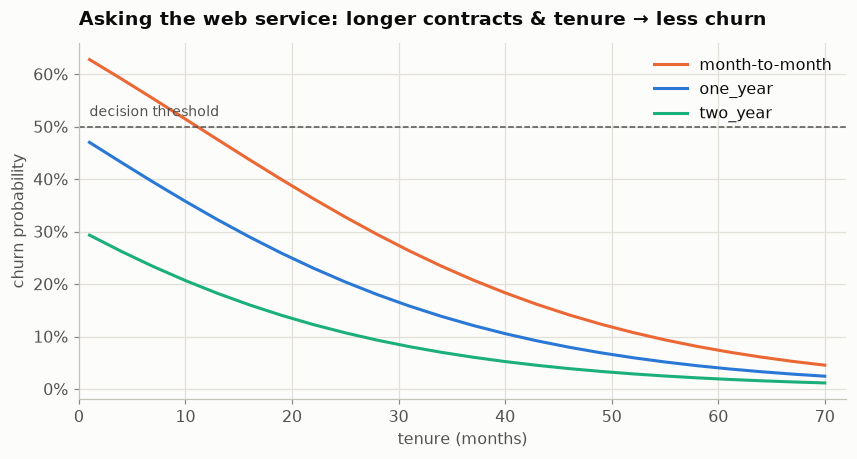

In [36]:
fig, ax = plt.subplots(figsize=(9, 4.2))
for contract, color in zip(contracts, [ORANGE, BLUE, AQUA]):
    ax.plot(list(tenures), curves[contract], color=color, label=contract)

ax.axhline(0.5, color=INK2, ls='--', lw=1)
ax.text(1, 0.52, 'decision threshold', color=INK2, fontsize=9)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlim(0, 72)
ax.set_xlabel('tenure (months)')
ax.set_ylabel('churn probability')
ax.legend(loc='upper right')
ax.set_title('Asking the web service: longer contracts & tenure → less churn')
plt.show()

## 5.6 How fast is it?

Each call is a full HTTP round-trip: open a connection, send JSON, parse, predict, answer.

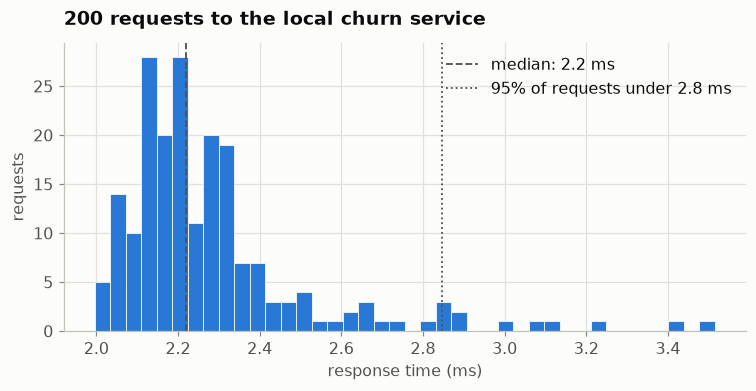

In [37]:
latencies_ms = []
for _ in range(200):
    start = time.perf_counter()
    requests.post(url, json=customer)
    latencies_ms.append((time.perf_counter() - start) * 1000)

median = np.median(latencies_ms)
p95 = np.percentile(latencies_ms, 95)

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(latencies_ms, bins=40, color=BLUE, edgecolor='white', lw=0.5)
ax.axvline(median, color=INK2, ls='--', lw=1.2, label=f'median: {median:.1f} ms')
ax.axvline(p95, color=INK2, ls=':', lw=1.2, label=f'95% of requests under {p95:.1f} ms')
ax.legend(loc='upper right')
ax.set_xlabel('response time (ms)')
ax.set_ylabel('requests')
ax.set_title('200 requests to the local churn service')
plt.show()

In [38]:
service.stop()

🛑 Server at http://127.0.0.1:9696 stopped


## 5.7 Preparing for production: gunicorn (Linux / macOS) and waitress (Windows)

When you run `python predict.py`, Flask prints:

```
WARNING: This is a development server. Do not use it in a production deployment.
Use a production WSGI server instead.
```

Flask's built-in server is made for *editing code*: it isn't built for many requests at once or
for security. In production a **WSGI server** runs our `app` (WSGI is the standard interface
between Python web apps and web servers):

| | **gunicorn** | **waitress** |
|---|---|---|
| Runs on | Linux, macOS (**not Windows**: it needs the Unix-only `fcntl` module) | everywhere, including Windows |
| Command | `gunicorn --bind=0.0.0.0:9696 predict:app` | `waitress-serve --listen=0.0.0.0:9696 predict:app` |
| Used here | inside Docker (Linux) | on Windows during development |

`predict:app` means *module `predict` (the file `predict.py`), variable `app`*.

Changing the server **doesn't make the service reachable from the internet**. It still runs on your
machine. For that we need a host (§8).

### 💡 Why did `!pip install gunicorn # and then use gunicorn --bind 0 predict_test:app` fail?

```
no such option: --bind
```

A line starting with `!` is handed to the operating system's **shell**. On Windows that's `cmd.exe`,
where **`#` doesn't start a comment**. pip received the whole line as arguments:
`install gunicorn # and then use gunicorn --bind 0 ...`, and `--bind` isn't a pip option.
Keep comments on their own line:

```python
# then start it with: gunicorn --bind=0.0.0.0:9696 predict:app
!pip install gunicorn
```

---
# 6. Python virtual environments: Pipenv *(5.5)*

## 6.1 Why we need virtual environments

Imagine one server that runs two services: our new churn service (needs **scikit-learn 1.9.1**) and an
old model trained years ago (needs **scikit-learn 0.24.2**). With one global Python only one version
can be installed, so one of them breaks. Remember from §3: **a pickled model must be loaded with the
same library version it was saved with.**

A **virtual environment** is a separate folder with its own Python packages, one per project, so
two versions of scikit-learn can live on the same computer.

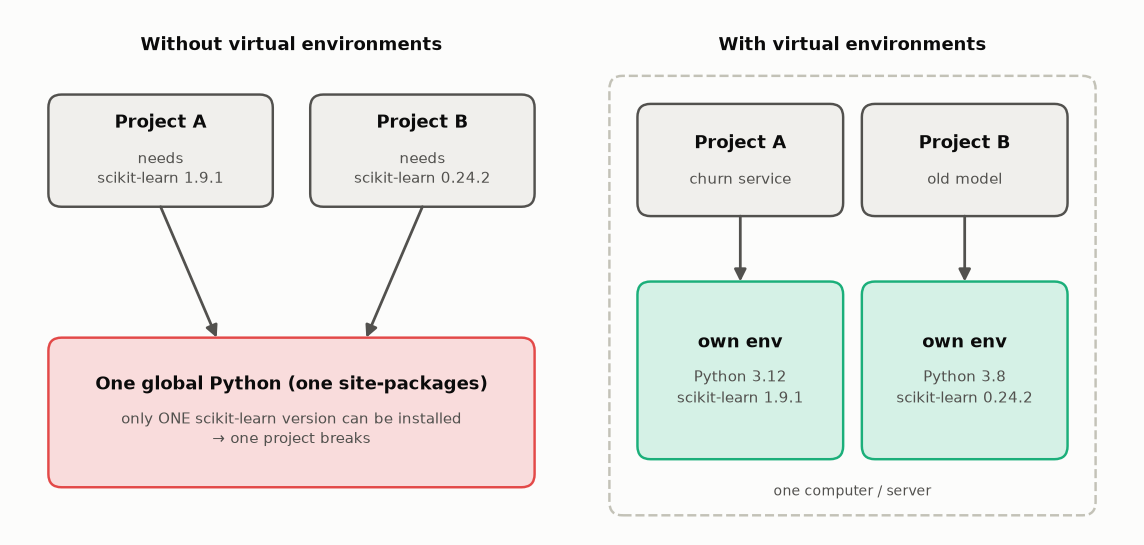

In [39]:
nh.draw_venv_isolation()

## 6.2 The tools: which one to use?

There are two kinds of tools. Some only **create isolated environments**; others also **manage
dependencies** (resolve versions, write a lock file). Pipenv, Poetry and uv **are not virtual
environments themselves**: they create and manage standard virtual environments for you.

| Tool | What it is | Installs other Python versions? | Lock file | 👍 Pros | 👎 Cons |
|------|-----------|:---:|:---:|---------|---------|
| **venv** | built into Python 3 | ❌ uses the Python that runs it | ❌ | nothing to install, standard | no locking; pair it with `pip freeze > requirements.txt` |
| **virtualenv** | the older, faster third-party version of venv | ❌ (can use other *installed* Pythons) | ❌ | fast, more options | mostly replaced by venv |
| **conda / mamba** | env + package manager from Anaconda | ✅ | ✅ (`conda-lock`, explicit files) | installs **non-Python** libs too (CUDA, GDAL, MKL); popular in data science | big; mixing `conda` and `pip` can break envs; Anaconda channel licence rules for large organisations (use conda-forge / miniforge) |
| **pipenv** | `pip` + `venv` + lock file | ⚠️ only if pyenv / asdf is installed | ✅ `Pipfile.lock` | simple, reproducible, hashes | resolver can be slow; less momentum today |
| **poetry** | dependency manager **and** packaging tool | ⚠️ mostly relies on an existing Python | ✅ `poetry.lock` | great for building & publishing libraries, `pyproject.toml` | more concepts to learn |
| **uv** | very fast all-in-one tool (written in Rust) | ✅ `uv python install 3.12` | ✅ `uv.lock` | **10–100× faster than pip**, manages Pythons, envs, locks; pip-compatible (`uv pip install`) | newer; still changing quickly |
| **pyenv** | Python **version** manager (not an env tool) | ✅ | ❌ | many Pythons side by side | Linux/macOS (use `pyenv-win` on Windows) |

**Python versions: conda vs venv.** You're right that conda (and uv) can **download and install**
any Python version (even Python 2.7) into an environment. `venv` can't download Python: it uses
the interpreter you run it with. If several Pythons are installed you can choose one, e.g. on
Windows `py -3.10 -m venv .venv`.

**Which is best nowadays?**
* 🥇 **uv** for new projects: fast, one tool for Python versions + envs + lock files.
* **conda** when you need non-Python binaries (GPU / CUDA stacks, geospatial libraries).
* **venv + pip** when you want zero extra tools.
* **Pipenv** (used here) is still a perfectly good, reproducible choice, and the ideas
  (a file of direct dependencies + a lock file) are the same in poetry and uv.

## 6.3 Pipenv step by step

```bash
# 1. install pipenv itself (once per computer)
pip install pipenv

# 2. in the project folder: create the env and add packages -> writes Pipfile + Pipfile.lock
pipenv install numpy pandas scikit-learn==1.9.1 flask requests gunicorn waitress

# 3. development-only tools (not needed to *run* the service)
pipenv install --dev awsebcli matplotlib ipykernel

# 4a. run one command inside the environment ...
pipenv run python train.py
pipenv run waitress-serve --listen=0.0.0.0:9696 predict:app

# 4b. ... or open a shell where the env is activated
pipenv shell
```

On **another computer** (a teammate, a server, a Docker image) after `git clone`:

```bash
pipenv install            # recreate the env from Pipfile.lock (add --dev for dev packages)
pipenv install --deploy   # same, but fail if Pipfile.lock is out of date (good for servers / CI)
```

Useful extras: `pipenv --venv` (where the env lives), `pipenv graph` (dependency tree),
`pipenv requirements > requirements.txt` (export the lock as pip format), `pipenv --rm` (delete the env).

## 6.4 `Pipfile` and `Pipfile.lock`

In [40]:
nh.show_file('Pipfile')

📄 **`Pipfile`**
```toml
[[source]]
url = "https://pypi.org/simple"
verify_ssl = true
name = "pypi"

[packages]
numpy = "*"
pandas = "*"
scikit-learn = "==1.9.1"
flask = "*"
requests = "*"
gunicorn = "*"
waitress = "*"

[dev-packages]
awsebcli = "*"
matplotlib = "*"
ipykernel = "*"

[requires]
python_version = "3.12"
```

* **`Pipfile`**: written **by you**. It lists your *direct* dependencies, usually with loose versions
  (`"*"` = any version). `[dev-packages]` are only needed for development.
* **`Pipfile.lock`**: written **by Pipenv**. It records the *exact* version of **every** package that
  got installed, including the dependencies of your dependencies, plus a **sha256 hash** of each file,
  so the next install is byte-for-byte the same (and safe from tampered packages).

**Commit both to git.** Never edit the lock file by hand. The difference in size shows why the lock matters:

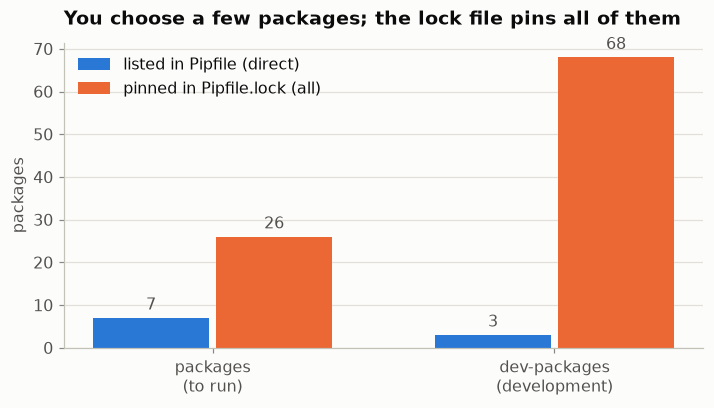

Pipfile.lock -> scikit-learn: version ==1.9.1, 43 file hashes


In [41]:
import tomllib

with open('Pipfile', 'rb') as f_in:
    pipfile = tomllib.load(f_in)
with open('Pipfile.lock', encoding='utf-8') as f_in:
    lock = json.load(f_in)

groups = ['packages\n(to run)', 'dev-packages\n(development)']
direct = [len(pipfile['packages']), len(pipfile['dev-packages'])]
pinned = [len(lock['default']), len(lock['develop'])]

fig, ax = plt.subplots(figsize=(7.5, 3.6))
x = np.arange(len(groups))
bars1 = ax.bar(x - 0.18, direct, width=0.34, color=BLUE, label='listed in Pipfile (direct)')
bars2 = ax.bar(x + 0.18, pinned, width=0.34, color=ORANGE, label='pinned in Pipfile.lock (all)')
ax.bar_label(bars1, padding=3, color=INK2)
ax.bar_label(bars2, padding=3, color=INK2)
ax.set_xticks(x, groups)
ax.grid(axis='x', visible=False)
ax.set_ylabel('packages')
ax.legend(loc='upper left')
ax.set_title('You choose a few packages; the lock file pins all of them')
plt.show()

sk = lock['default']['scikit-learn']
print(f"Pipfile.lock -> scikit-learn: version {sk['version']}, {len(sk['hashes'])} file hashes")

## 6.5 Check: which environment is this notebook running in?

That `'1.9.1'` you printed in the original notebook is exactly this check:

In [42]:
from pathlib import Path
print('environment:', Path(sys.prefix).name)      # the Pipenv virtualenv folder
for package in ['scikit-learn', 'numpy', 'pandas', 'flask', 'gunicorn', 'waitress']:
    print(f'  {package:13} {metadata.version(package)}')

environment: Deployment-ML-Model-Project-fb4rSXqG
  scikit-learn  1.9.1
  numpy         2.5.4
  pandas        3.0.6
  flask         3.1.3
  gunicorn      26.2.0
  waitress      3.0.2


## 6.6 Why is there also a `requirements.txt`?

The **service** needs far fewer packages than development does (no pandas, matplotlib, Jupyter or
the AWS CLI). `requirements.txt` lists only what the Docker image needs to **serve** the model, with
pinned versions. You can also generate it from the lock with `pipenv requirements`.

In [43]:
nh.show_file('requirements.txt')

📄 **`requirements.txt`**
```text
# Packages needed to *serve* the model (installed in the Docker image).
# Versions are pinned: the model was pickled with scikit-learn 1.9.1 and must be
# loaded with the same version. Training / notebook packages live in the Pipfile.
scikit-learn==1.9.1
numpy==2.5.4
flask==3.1.3
gunicorn==26.2.0
```

---
# 7. Environment management: Docker *(5.6)*

## 7.1 Why Python environments are not enough

A virtual environment isolates **Python packages**. A model also depends on things **outside**
Python, which pip can't install:

* 🐧 **The operating system.** You develop on Windows 11; the server runs Ubuntu 22.04.
  Paths, line endings and available tools all differ.
* 🐍 **The Python interpreter itself.** The server has Python 3.8, your code needs 3.12.
* 📚 **System libraries.** LightGBM needs `libgomp`, PostgreSQL drivers need `libpq`, OCR needs
  `tesseract`, GPU models need CUDA. Pipenv can't install any of them.
* 🧩 **Several services on one server** need different Pythons and different system libraries.
* 😩 **"It works on my machine."** Each developer's laptop is set up slightly differently.

**Docker** packages **everything**: OS files, Python, system libraries, Python packages, our code
and the model, all in one **image**. Anything that runs Docker runs the image the same way: your
laptop, a colleague's Mac, a server in AWS.

## 7.2 Does Docker run Linux, even on Windows?

Mostly yes ✅. A container **shares the kernel of the machine it runs on**. Almost all images
(including `python:3.12-slim`) are **Linux** images, so they need a Linux kernel:

* **Linux host:** containers use the host's kernel directly.
* **Windows / macOS host:** Docker Desktop starts a small, hidden **Linux virtual machine**
  (on Windows through **WSL 2**), and the Linux containers run inside it. That's why Docker
  "creates Linux-like things" on Windows.
* **Windows containers exist** (based on *Windows Server Core* / *Nano Server*), but they need a
  Windows host. They're server images, not a Windows 11 desktop.
* **macOS containers:** not really. There are no official macOS images.

So your big picture needs one correction. **Every container on a host uses that host's kernel**,
so containers can run *different Linux distributions*, but not different operating systems:

| Host machine | ✅ containers can be | ❌ containers can't be |
|---|---|---|
| Ubuntu 18.04 | Ubuntu 16.04, Ubuntu 24.04, Debian, Alpine, Fedora, … (any Linux userland) | Windows 11, macOS |
| Windows 11 + Docker Desktop | any Linux image (through WSL 2), *or* Windows Server images in "Windows containers" mode | macOS |
| macOS + Docker Desktop | any Linux image (through a Linux VM) | Windows, macOS |

For a full, different OS (Windows 11 desktop on a Linux machine) you need a **virtual machine** ⬇️

## 7.3 Docker vs virtual machines

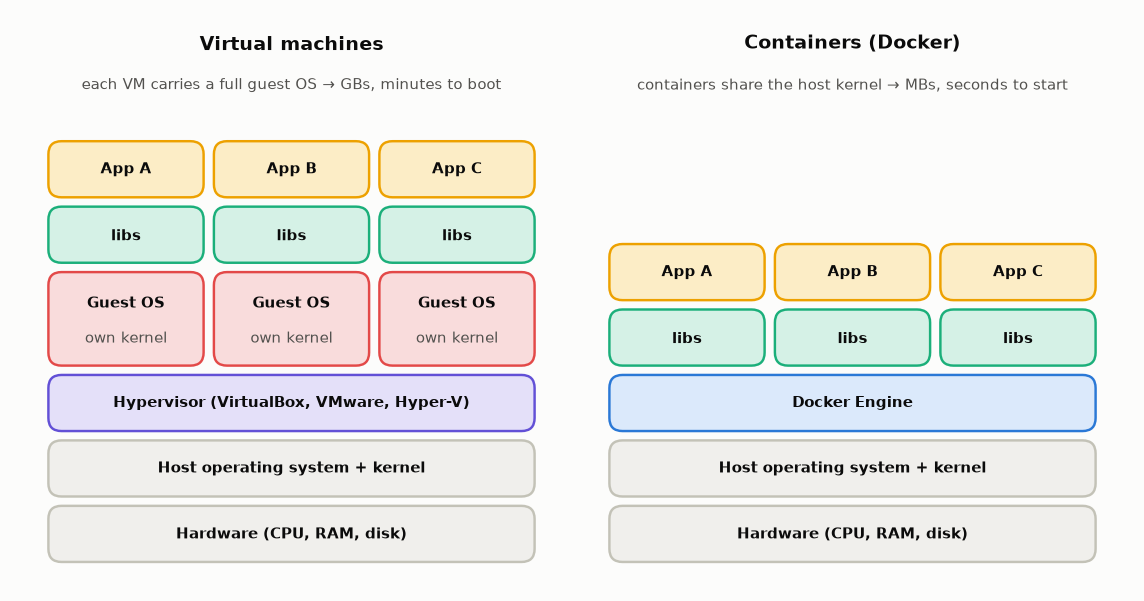

In [44]:
nh.draw_vm_vs_containers()

| | **Virtual machine** | **Docker container** |
|---|---|---|
| Virtualises | the **hardware**: each VM boots a full OS with its own kernel | the **OS**: processes isolated from each other, sharing the host kernel |
| Size | gigabytes | megabytes to a few hundred MB |
| Start-up | minutes | seconds or less |
| Other OS (e.g. Windows on Linux)? | ✅ yes | ❌ same kernel family only |
| Isolation | very strong | strong, but weaker than a VM |
| Typical use | run a different OS, strong security boundaries, legacy software | package and ship **applications**, microservices, CI, ML model serving |

They work together: cloud providers run your containers **inside VMs** (EC2 instances, §8).

## 7.4 Images vs containers

You got it right ✅. An **image** is a fixed, read-only template. A **container** is a running
instance of an image, and you can start **many containers from one image**. It's like a class and
its objects, or a recipe and the cakes you bake from it.

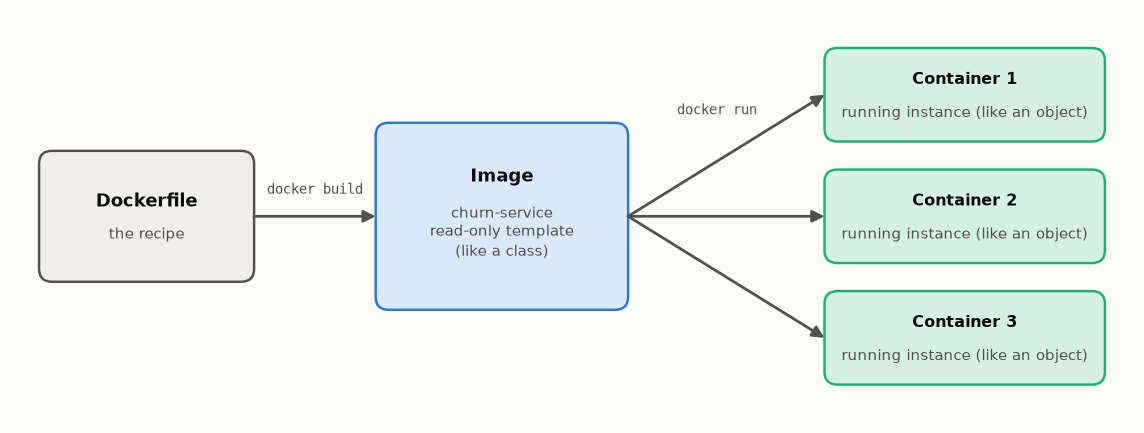

In [45]:
nh.draw_image_vs_containers()

* `docker build` turns a **Dockerfile** into an **image**.
* `docker run` creates and starts a **container** from an image.
* Images are shared through registries such as **[Docker Hub](https://hub.docker.com)**. With Docker
  installed you can run any published software (Python, PostgreSQL, even VLC) **without installing
  it or its dependencies** on your machine. You can create an account and publish your own images too.

## 7.5 Running a Python image

```bash
docker run -it --rm python:3.12-slim
```

| Part | Meaning |
|------|---------|
| `docker run` | create a container from an image and start it (the image is downloaded first if needed) |
| `-i` | *interactive*: keep the input (STDIN) open so you can type |
| `-t` | allocate a *terminal* (TTY), so you get a proper prompt |
| `--rm` | **delete the container when it stops** (no leftover containers) |
| `python:3.12-slim` | image `python`, **tag** `3.12-slim` = Python 3.12 on a minimal Debian |

The image's default command is `python`, so you land in a Python prompt. To get a Linux shell
instead, override it: `docker run -it --rm python:3.12-slim bash` (or `--entrypoint=bash`).

> 📝 The original course used `python:3.8.12-slim`. Python 3.8 reached end-of-life in Oct 2024, so
> this project uses **3.12**, the same version as the Pipenv environment.

## 7.6 Installing packages in an image

**1. Temporarily, inside a running container:**
```bash
docker run -it --rm python:3.12-slim bash
# now inside the container:
pip install flask requests
python                   # flask is available ... until you exit
```
Because of `--rm` (and because containers are created fresh from the image) **the installation is
gone when the container stops**. The image itself never changed.

**2. Permanently, by building your own image with a Dockerfile:**
```dockerfile
FROM python:3.12-slim
RUN pip install flask requests
```
```bash
docker build -t my-python .      # -t = name (tag) of the new image; . = folder with the Dockerfile
docker run -it --rm my-python    # flask is always there
```

## 7.7 The Dockerfile of our service, line by line

In [46]:
nh.show_file('Dockerfile')

📄 **`Dockerfile`**
```dockerfile
# Base image: Debian "slim" Linux with Python 3.12 already installed
FROM python:3.12-slim

# All following commands run inside /app (created if it doesn't exist)
WORKDIR /app

# Install the Python dependencies first: this layer is cached and only rebuilt
# when requirements.txt changes, not every time the code changes
COPY requirements.txt ./
RUN pip install --no-cache-dir -r requirements.txt

# Copy the service code and the trained model into /app
COPY ["predict.py", "model_C=1.0.bin", "./"]

# Documentation: the service listens on port 9696 inside the container
EXPOSE 9696

# Start the production web server when a container starts
ENTRYPOINT ["gunicorn", "--bind=0.0.0.0:9696", "predict:app"]
```

| Instruction | What it does |
|-------------|--------------|
| `FROM python:3.12-slim` | start from this base image (OS + Python). Every Dockerfile starts with `FROM` |
| `WORKDIR /app` | **set the current directory inside the image** for all following instructions (`RUN`, `COPY`, `ENTRYPOINT`), creating it if needed. Like `mkdir -p /app && cd /app`, but it persists. Our files go to `/app` instead of being mixed with system files in `/` |
| `COPY requirements.txt ./` | copy a file **from your project folder into the image**. `./` is relative to `WORKDIR`, so it lands at `/app/requirements.txt` |
| `RUN pip install ...` | run a command **while building** the image; the result is saved in the image |
| `COPY ["predict.py", "model_C=1.0.bin", "./"]` | JSON form: several sources, the **last item is the destination**. Handy for names with special characters |
| `EXPOSE 9696` | **documentation only**: "this container listens on 9696". It does **not** open the port; `-p` does that (§7.9) |
| `ENTRYPOINT [...]` | the command executed when a **container starts**: gunicorn serving `predict:app` on port 9696 |

**Why copy `requirements.txt` before the code?** Docker caches each instruction as a *layer*. If
only `predict.py` changes, Docker reuses the cached (slow) `pip install` layer and the rebuild takes
seconds.

**`ENTRYPOINT` vs `CMD`:** both set the start command. Arguments after the image name in
`docker run` *replace* `CMD` but are *appended* to `ENTRYPOINT`.

**`.dockerignore`** keeps unnecessary files (data, notebooks, `.git`) out of the build:

In [47]:
nh.show_file('.dockerignore')

📄 **`.dockerignore`**
```
# Files that are NOT sent to Docker when building the image
# (the image only needs predict.py, the model and requirements.txt)
.git
.gitignore
.elasticbeanstalk
.backup_original
.ipynb_checkpoints
__pycache__
*.ipynb
data/
images/
```

## 7.8 Do we need a virtual environment inside Docker?

**Usually no** ✅. The container already isolates everything, and it contains only one Python for
one application, so there's nothing to conflict with. We just `pip install` into the container's Python.

Reasons you *might* still use one:
* **Multi-stage builds:** build a venv in a "builder" image (with compilers), then copy only the
  venv into a small runtime image.
* **Base images with an OS-managed Python** (e.g. `ubuntu` + `apt install python3`): recent Debian/Ubuntu
  block system-wide `pip install` (*externally-managed-environment*, PEP 668).
  (Official `python:*` images don't have this problem.)
* **The same workflow as development**, installing straight from the lock file. With Pipenv,
  `--system` installs into the container's Python instead of creating a venv:

```dockerfile
FROM python:3.12-slim
RUN pip install pipenv
WORKDIR /app
COPY ["Pipfile", "Pipfile.lock", "./"]
RUN pipenv install --system --deploy     # exact versions from the lock, no venv
COPY ["predict.py", "model_C=1.0.bin", "./"]
EXPOSE 9696
ENTRYPOINT ["gunicorn", "--bind=0.0.0.0:9696", "predict:app"]
```

## 7.9 Build and run the image, and which port is which

```bash
docker build -t churn-service .
docker run -it --rm -p 127.0.0.1:8080:9696 churn-service
```

| Option | Meaning |
|--------|---------|
| `-t churn-service` | give the image a name |
| `.` | the *build context*: the folder sent to Docker (minus `.dockerignore`) |
| `--name churn-container` | *(optional)* give the container a name, e.g. for `docker stop churn-container` |
| `-p 127.0.0.1:8080:9696` | **port mapping**: `[host IP]:[host port]:[container port]` |

**Why two ports?** A container has **its own network**, like a separate small computer. gunicorn
listens on port **9696 inside the container**. Nothing outside can reach it until we **publish**
that port: `-p` tells Docker to forward a port **on your computer** to the container's port.

* **9696 = container port**: where the service listens, fixed in the Dockerfile.
* **8080 = host port**: what *you* (the client) connect to, any free port you choose.
* **`127.0.0.1`** (optional): only programs on your computer can connect. Without it
  (`-p 8080:9696`) other machines in your network can connect too.
* Most people simply use `-p 9696:9696` (same number on both sides) to avoid confusion.

This is also why gunicorn binds to **`0.0.0.0`** inside the container: with `127.0.0.1` it would only
accept connections from *inside* the container, and the forwarded traffic couldn't reach it.

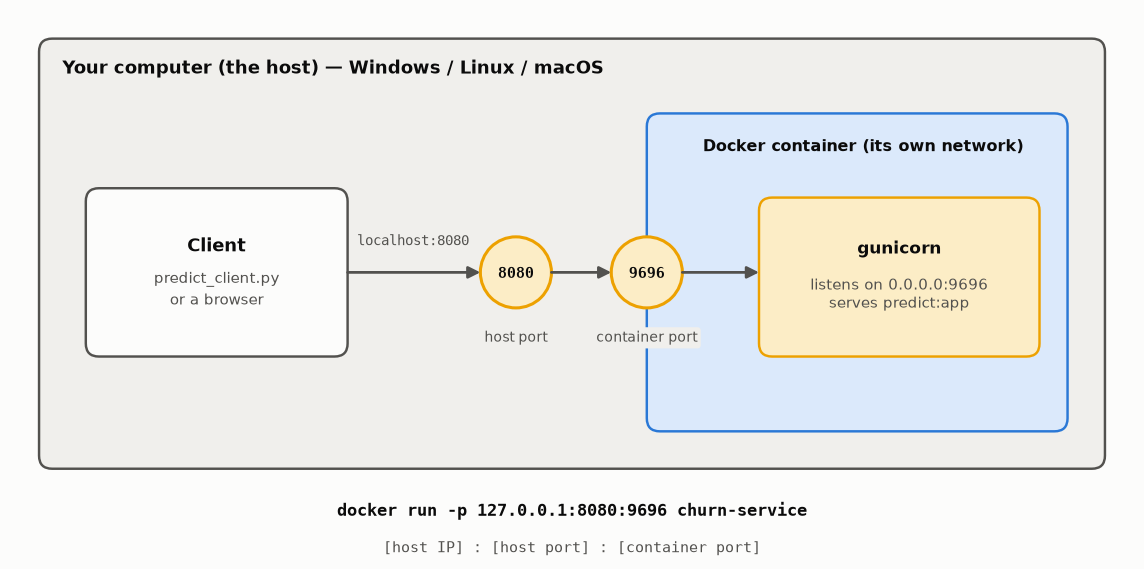

In [48]:
nh.draw_port_mapping()

### Server side vs client side, step by step

| Step | Side | Command |
|------|------|---------|
| 1 | server | train and save the model: `pipenv run python train.py` |
| 2 | server | build the image: `docker build -t churn-service .` |
| 3 | server | start a container: `docker run -it --rm -p 127.0.0.1:8080:9696 churn-service` |
| 4 | client | send a request: `python predict_client.py --host localhost:8080` |
| 5 | server | stop it: `Ctrl+C` in its terminal, or `docker stop <container>` |

Here the "server" and the "client" are two terminals on the same computer. In §8 the server side
moves to AWS and only the `--host` changes.

**Verified output** (from building and running this project's image):
```text
$ docker run -d --rm --name churn-test -p 127.0.0.1:8080:9696 churn-service
$ docker logs churn-test
[INFO] Starting gunicorn 26.2.0
[INFO] Listening at: http://0.0.0.0:9696 (1)
[INFO] Booting worker with pid: 7

$ python predict_client.py --host localhost:8080
POST http://localhost:8080/predict
Response: {'churn': True, 'churn_probability': 0.6278927307895446}
Churn probability 62.8% -> send a discount offer
```

Call it with curl (from the project folder, using `customer.json`):
```bash
curl.exe -X POST -H "Content-Type: application/json" -d "@customer.json" http://localhost:8080/predict
```

## 7.10 Everyday Docker commands

| Command | Does |
|---------|------|
| `docker images` | list images |
| `docker ps` / `docker ps -a` | list running / all containers |
| `docker logs <container>` | show a container's output |
| `docker exec -it <container> bash` | open a shell inside a running container |
| `docker stop <container>` | stop a container |
| `docker rmi <image>` | delete an image |
| `docker system prune` | clean up stopped containers and unused data |
| `docker tag churn-service <user>/churn-service:1.0` → `docker push <user>/churn-service:1.0` | publish to Docker Hub (after `docker login`) |

---
# 8. Deployment to the cloud: AWS Elastic Beanstalk *(5.7, optional)*

## 8.1 Where can we deploy? Comparing the options

Our service is a Docker image, so it runs almost anywhere. The options differ mostly in **how
much they do for you**:

| Provider | Typical service for a container / model | Good for | Notes |
|----------|------------------------------------------|----------|-------|
| **AWS** | Elastic Beanstalk, ECS / Fargate, Lambda, SageMaker | the biggest ecosystem, lots of jobs ask for it | many knobs; set up billing alerts |
| **Google Cloud (GCP)** | Cloud Run, Vertex AI | the simplest container hosting (Cloud Run scales to zero) | pay per request |
| **Microsoft Azure** | App Service, Container Apps, Azure ML | companies already on Microsoft | similar to AWS |
| **Heroku** | Dynos (`git push` or a container) | very simple PaaS | no free tier since Nov 2022 |
| **PythonAnywhere** | hosted Python web apps | beginners, small Flask apps | no Docker support; limited free tier |
| **Render / Fly.io / Railway** | container hosting | quick hobby projects | small free / cheap plans |
| **Hugging Face Spaces** | Docker or Gradio / Streamlit apps | ML demos | free CPU tier, public by default |

**Which one is best?** There's no single winner. For learning, **AWS Elastic Beanstalk** (used here)
shows the classic pieces: servers, load balancer, scaling. **Google Cloud Run** is the easiest way
to run a container in production. The **Docker image is the same everywhere**, which is the point
of §7.

## 8.2 The idea of Elastic Beanstalk

You give Elastic Beanstalk (EB) your **code + Dockerfile**; it does the infrastructure work:

* creates **EC2 servers** (virtual machines) and builds & runs your Docker image on them,
* puts a **load balancer** in front, with one **public URL**, that spreads requests across the servers,
* **monitors health** (calling our `GET /` endpoint) and replaces broken servers,
* **auto-scales**: **scaling out** = adding servers when traffic grows (e.g. the marketing campaign
  starts), **scaling in** = removing them when it's quiet, so you don't pay for idle machines.
  (*Scaling up/down* strictly means using a bigger/smaller machine; *out/in* means more/fewer machines.)

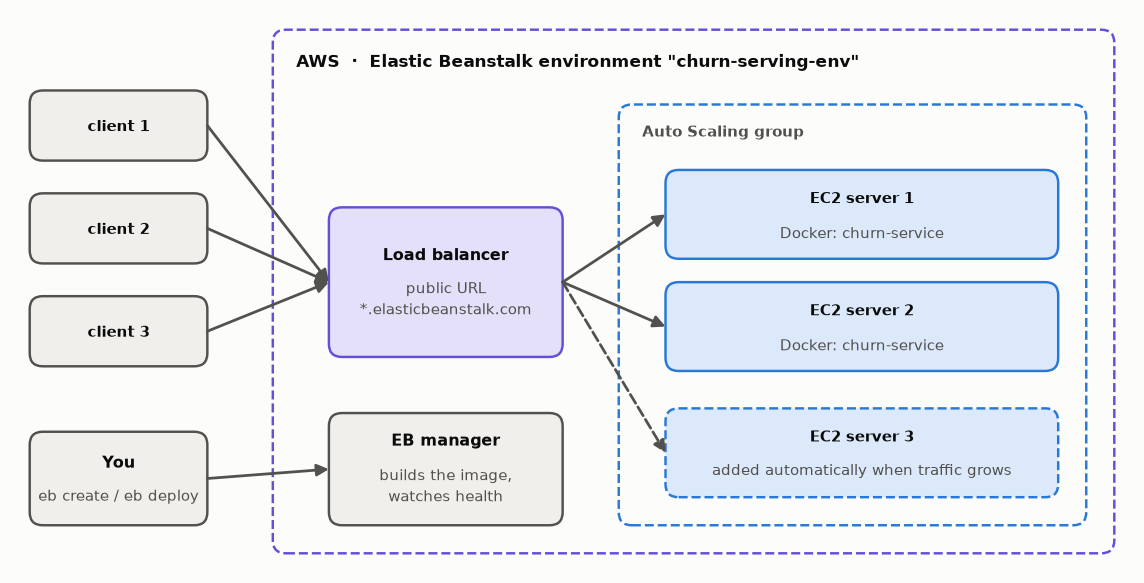

In [49]:
nh.draw_elastic_beanstalk()

## 8.3 Step by step

**0. Prerequisites:** an AWS account and an IAM user with an **access key**. The EB CLI asks for it
the first time (or run `aws configure`). 🔐 **Never commit access keys to git.**

**1. Install the EB command-line tool** (a dev dependency: only your laptop needs it)
```bash
pipenv install --dev awsebcli
pipenv shell                     # the following commands run inside the env
```

**2. Create the EB application** (once). This writes `.elasticbeanstalk/config.yml`:
```bash
eb init -p docker -r eu-north-1 churn-serving
#        │         │              └─ application name
#        │         └─ AWS region (Stockholm)
#        └─ platform: Docker (EB will use our Dockerfile)
```

**3. Test locally first** (optional):
```bash
eb local run --port 9696
```
⚠️ `eb local` is only supported on **Linux and macOS**. On Windows, use the `docker build` / `docker run` commands from §7.9; they test the same image.

**4. Deploy for real:**
```bash
eb create churn-serving-env      # creates servers, load balancer, ... (takes a few minutes)
eb status churn-serving-env      # shows the health and the public CNAME (URL)
```

**5. Use it from anywhere.** Only the host changes:
```bash
python predict_client.py --host churn-serving-env.eba-xxxxxxxx.eu-north-1.elasticbeanstalk.com
```

**6. Update, inspect, delete:**
```bash
eb deploy                        # upload a new version after changing the code / model
eb logs                          # server logs
eb terminate churn-serving-env   # ⚠️ delete everything when you're done -> stops the costs
```

> 📦 **What gets uploaded?** If the project is a **git** repository, EB deploys only the **last
> commit** (uncommitted changes are ignored!) unless an **`.ebignore`** file exists. This project has
> one, so EB uploads the working folder minus the files listed in `.ebignore`.

## 8.4 Costs & security

* 💸 A load-balanced environment costs money **even when nobody uses it** (EC2 + load balancer).
  Run `eb terminate` after experimenting, and set up an AWS **billing alert**. For a cheaper
  test, use `eb create --single` (one server, no load balancer).
* 🔓 The URL is **public**: anyone who knows it can call the model. Real services add
  authentication (API keys), HTTPS, and input validation.

---
# 9. Summary *(5.8)*

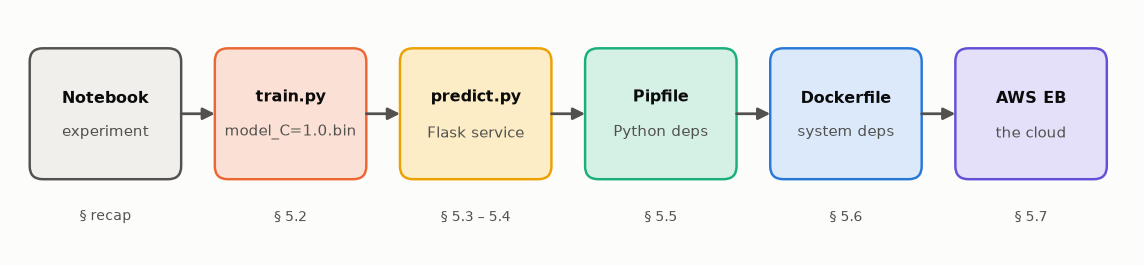

In [50]:
nh.draw_project_pipeline()

| Step | What we did | Files |
|------|-------------|-------|
| ✅ **Save the model** | `pickle` the vectorizer + model together; load it in another process | `train.py`, `model_C=1.0.bin` |
| ✅ **Web service** | Flask turns `predict()` into `POST /predict`; `requests` / curl / browser to call it | `ping.py`, `predict.py`, `predict_client.py` |
| ✅ **Production server** | gunicorn (Linux) / waitress (Windows) instead of Flask's dev server | `Dockerfile` |
| ✅ **Python dependencies** | Pipenv: `Pipfile` (what you want) + `Pipfile.lock` (exactly what you get) | `Pipfile`, `Pipfile.lock`, `requirements.txt` |
| ✅ **System dependencies** | Docker image: OS + Python + packages + code + model | `Dockerfile`, `.dockerignore` |
| ✅ **Cloud** | Elastic Beanstalk: servers, load balancer, scaling, public URL | `.ebignore`, `.elasticbeanstalk/` |

**The key insight:** the client code never changed. Only the address did:
`localhost:9696` → `localhost:8080` (Docker) → `….elasticbeanstalk.com` (cloud).

---
# 10. Explore more *(5.9)*

* **FastAPI instead of Flask.** It validates the input automatically and generates interactive docs at `/docs`:
  ```python
  from fastapi import FastAPI
  from pydantic import BaseModel

  class Customer(BaseModel):
      contract: str
      tenure: int
      monthlycharges: float
      # ... the other 16 fields

  app = FastAPI()

  @app.post('/predict')
  def predict(customer: Customer):
      X = dv.transform([customer.model_dump()])
      probability = float(model.predict_proba(X)[0, 1])
      return {'churn_probability': probability, 'churn': probability >= 0.5}
  # run: uvicorn predict_fastapi:app --host 0.0.0.0 --port 9696
  ```
* **Other environment managers:** redo §6 with `uv` (`uv init`, `uv add scikit-learn==1.9.1 flask`,
  `uv run python train.py`), `venv + pip`, conda or poetry.
* **Other clouds:** deploy the *same* Docker image to Google Cloud Run, Azure Container Apps, Render,
  Fly.io or Hugging Face Spaces.
* **Make it production-grade:** input validation, logging, automated tests for `/predict`, a CI
  pipeline that builds the image on every push, model versioning (`model_v2.bin`) and monitoring of
  prediction drift.